# Sudoku Model Predictions

Load an MLP or transformer checkpoint saved by `train.py` (or `grid.py`) and compare a held-out test prediction with its solution.

In [1]:
from pathlib import Path

import torch
from datasets import Features, Value, load_dataset

from model import NeuralNetwork as Transformer
from model_MLP import NeuralNetwork as MLP
from utils import plot_sudoku

MODELS = {"mlp": MLP, "transformer": Transformer}

/home/lucchi0001/miniforge3/envs/ml/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# e.g. sudoku_model_mlp.pt, sudoku_model_transformer.pt or grid_results/best_model.pt
model_path = Path("sudoku_model_transformer.pt")
checkpoint = torch.load(model_path, map_location="cpu", weights_only=True)

if "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

# Checkpoints from train.py record the model type; older ones and grid.py
# checkpoints do not, so recognize the transformer by its attention blocks.
model_name = checkpoint.get("model")
if model_name is None:
    model_name = "transformer" if any(k.startswith("blocks.") for k in state_dict) else "mlp"

if "layer_sizes" in checkpoint:
    layer_sizes = checkpoint["layer_sizes"]
elif model_name == "transformer":
    # One block per entry, sized by its feed-forward width.
    layer_sizes = [
        value.shape[0]
        for name, value in state_dict.items()
        if name.startswith("blocks.") and name.endswith(".mlp.0.weight")
    ]
else:
    layer_sizes = [
        value.shape[0]
        for name, value in state_dict.items()
        if name.endswith(".weight")
    ][:-1]

net = MODELS[model_name](layer_sizes)
net.load_state_dict(state_dict)
net.eval()
print(f"Loaded {model_name} from {model_path} with layer sizes {layer_sizes}")

Loaded transformer from sudoku_model_transformer.pt with layer sizes [2048, 2048, 2048, 2048]


In [3]:
features = Features({"puzzle": Value("string"), "solution": Value("string")})
ds = load_dataset("certen/Sudoku-1M-Puzzles", features=features)

# Match the untouched test split used by the tuning search.
n_training = int(0.9 * len(ds["train"]))
n_held_out = len(ds["train"]) - n_training
order = torch.randperm(n_held_out, generator=torch.Generator().manual_seed(2026))
test_indices = order[n_held_out // 2:]
example_index = 0
example = ds["train"][n_training + test_indices[example_index].item()]
puzzle = torch.tensor([int(c) for c in example["puzzle"]], dtype=torch.long)
ground_truth = torch.tensor([int(c) for c in example["solution"]], dtype=torch.long)

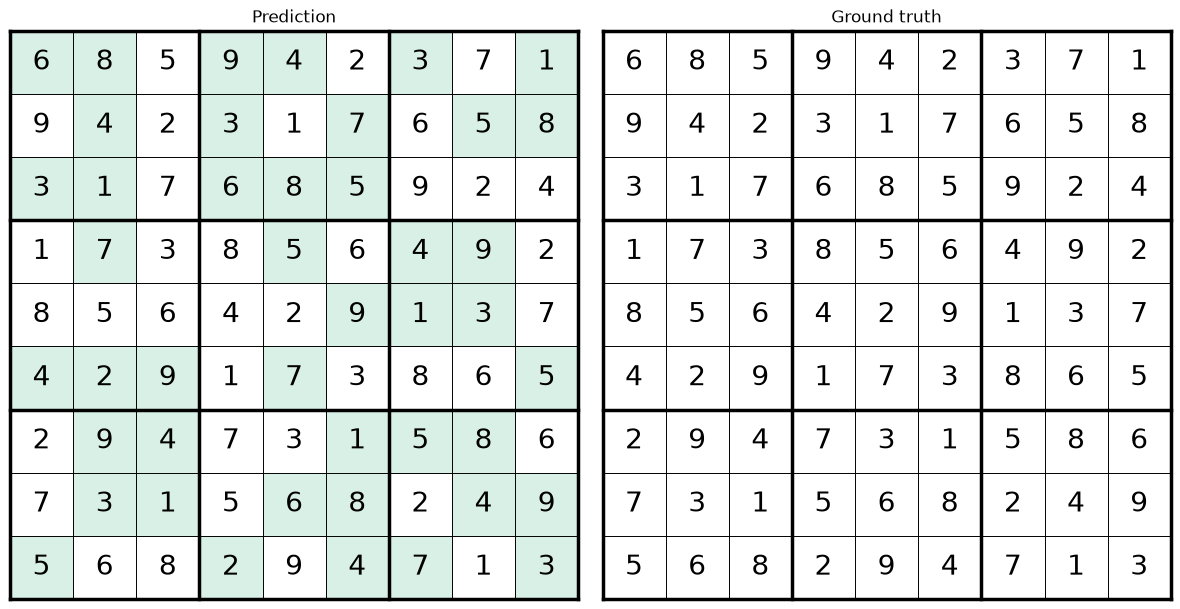

In [4]:
import matplotlib.pyplot as plt

# net(puzzle.unsqueeze(0)) returns a tensor of size [1, n_classes, grid_size]
with torch.inference_mode():
    prediction = net(puzzle.unsqueeze(0)).argmax(dim=1) + 1 # take argmax across classes (dim=1)

plot_sudoku(prediction, ground_truth, puzzle)
plt.show()